# Métricas de evaluación y clases desbalanceadas

Una métrica traduce el desempeño de un modelo en un número, y la elección de la métrica define qué significa un buen modelo. No hay una métrica universal: depende del tipo de problema, del balance entre clases y del costo de cada tipo de error {cite}`kuhn2013,james2021`.

## Métricas para regresión

El error absoluto medio (MAE) promedia los valores absolutos de los residuos y está en las unidades de la respuesta. La raíz del error cuadrático medio (RMSE) penaliza más los errores grandes. Ambas van de 0 a infinito, son mejores cuanto más bajas y no dependen del signo de los errores; si no se toma el valor absoluto, el promedio de los residuos es el error de sesgo medio (MBE), que indica si el modelo sobrestima o subestima sistemáticamente, aunque los errores positivos y negativos se compensan. El coeficiente de determinación $R^2$ es la proporción de la varianza de la respuesta explicada por el modelo; el $R^2$ ajustado penaliza el número de predictores. La función de pérdida de Huber combina el comportamiento cuadrático para errores pequeños con el lineal para errores grandes, y es robusta a los atípicos.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import metrics
plt.rcParams['figure.dpi'] = 100
rng = np.random.default_rng(2)

y = rng.gamma(3, 15, 300)                              # caudal observado (m³/s)
modelos = {'sin sesgo': y + rng.normal(0, 8, 300),
           'con sesgo (+5)': y + 5 + rng.normal(0, 8, 300),
           'con 5 errores grandes': y + rng.normal(0, 4, 300) + np.where(np.arange(300) < 5, 80, 0)}
print(f'{"modelo":24s} {"MAE":>6s} {"RMSE":>6s} {"MBE":>6s} {"R2":>6s}')
for nom, p in modelos.items():
    print(f'{nom:24s} {metrics.mean_absolute_error(y, p):6.2f} {np.sqrt(metrics.mean_squared_error(y, p)):6.2f} '
          f'{np.mean(p - y):6.2f} {metrics.r2_score(y, p):6.3f}')

modelo                      MAE   RMSE    MBE     R2
sin sesgo                  6.37   8.14   0.02  0.903
con sesgo (+5)             7.45   9.25   4.32  0.874
con 5 errores grandes      4.62  11.18   0.91  0.817


El tercer modelo tiene un MAE menor que el primero pero un RMSE mayor: unos pocos errores grandes pesan mucho en el RMSE. Reportar ambas métricas y el sesgo da una imagen más completa que cualquiera por separado.

## Métricas para clasificación

En clasificación binaria se cruzan las clases reales y las predichas en la matriz de confusión, con cuatro casillas: verdaderos positivos (VP), falsos positivos (FP), verdaderos negativos (VN) y falsos negativos (FN). De ella salen la exactitud, $(VP+VN)/n$; la sensibilidad o exhaustividad (recall), $VP/(VP+FN)$, la fracción de deslizamientos reales que el modelo detecta; la especificidad, $VN/(VN+FP)$; la precisión, $VP/(VP+FP)$, la fracción de alarmas que son reales; y el puntaje F1, la media armónica de precisión y sensibilidad.

La mayoría de los clasificadores entregan una probabilidad y la clase depende de un umbral, por defecto 0.5. La curva ROC grafica la sensibilidad contra la tasa de falsos positivos (1 - especificidad) para todos los umbrales, y el área bajo ella (AUC) resume la capacidad de discriminación: es la probabilidad de que un caso positivo elegido al azar reciba una probabilidad mayor que un negativo elegido al azar. Un AUC de 0.5 equivale al azar y uno de 1, a una discriminación perfecta. Es la métrica más usada en los mapas de susceptibilidad. La curva de precisión-sensibilidad es más informativa cuando los positivos son raros.

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

def inventario(n, prop_pos, semilla=0):
    r = np.random.default_rng(semilla)
    pend = r.gamma(4, 6, n); dist = r.exponential(250, n); lluv = r.normal(2500, 500, n)
    eta = 0.12 * pend - 0.004 * dist + 0.0012 * lluv
    corte = np.quantile(eta + r.logistic(0, 1, n), 1 - prop_pos)    # fija la proporción de positivos
    y = (eta + r.logistic(0, 1, n) > corte).astype(int)
    return np.column_stack([pend, dist, lluv]), y

X, yb = inventario(6000, 0.05)
X_tr, X_te, y_tr, y_te = train_test_split(X, yb, test_size=0.4, random_state=0, stratify=yb)
lr = LogisticRegression(max_iter=1000).fit(X_tr, y_tr)
p = lr.predict_proba(X_te)[:, 1]
pred = (p >= 0.5).astype(int)
print(f'Proporción de deslizamientos: {yb.mean():.3f}')
print('Matriz de confusión (filas: real, columnas: predicho):'); print(metrics.confusion_matrix(y_te, pred))
print(f'Exactitud {metrics.accuracy_score(y_te, pred):.3f}   sensibilidad {metrics.recall_score(y_te, pred):.3f}   '
      f'precisión {metrics.precision_score(y_te, pred, zero_division=0):.3f}   F1 {metrics.f1_score(y_te, pred):.3f}   AUC {metrics.roc_auc_score(y_te, p):.3f}')
print(f'Un modelo que siempre dice "no hay deslizamiento" tendría exactitud {1 - y_te.mean():.3f}')

Proporción de deslizamientos: 0.049
Matriz de confusión (filas: real, columnas: predicho):
[[2269   14]
 [  93   24]]
Exactitud 0.955   sensibilidad 0.205   precisión 0.632   F1 0.310   AUC 0.883
Un modelo que siempre dice "no hay deslizamiento" tendría exactitud 0.951


Con un 5 % de deslizamientos, la exactitud es engañosa: un modelo que nunca predice deslizamientos acierta el 95 %. La sensibilidad con el umbral de 0.5 es baja, aunque el AUC muestra que el modelo sí discrimina. El problema no es el modelo sino el umbral. La celda siguiente dibuja las curvas ROC y de precisión-sensibilidad y muestra cómo cambian las métricas con el umbral.

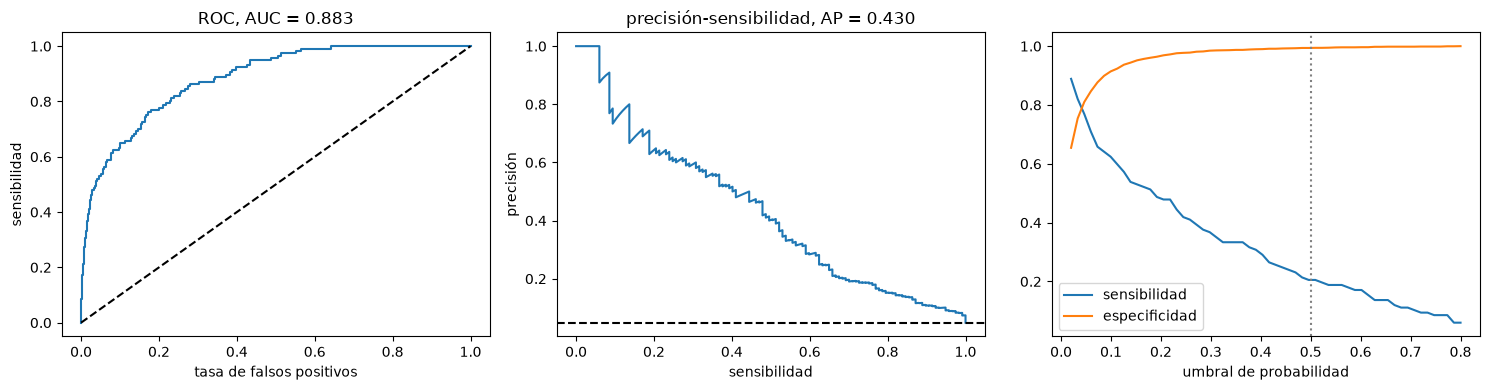

Umbral que maximiza el índice de Youden (sensibilidad + especificidad - 1): 0.049


In [3]:
fpr, tpr, thr = metrics.roc_curve(y_te, p)
prec, rec, thr_pr = metrics.precision_recall_curve(y_te, p)
umbrales = np.linspace(0.02, 0.8, 60)
sens = [metrics.recall_score(y_te, p >= u) for u in umbrales]
espe = [metrics.recall_score(1 - y_te, p < u) for u in umbrales]
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
axs[0].plot(fpr, tpr); axs[0].plot([0, 1], [0, 1], 'k--'); axs[0].set_xlabel('tasa de falsos positivos'); axs[0].set_ylabel('sensibilidad')
axs[0].set_title(f'ROC, AUC = {metrics.roc_auc_score(y_te, p):.3f}')
axs[1].plot(rec, prec); axs[1].axhline(y_te.mean(), color='k', ls='--'); axs[1].set_xlabel('sensibilidad'); axs[1].set_ylabel('precisión')
axs[1].set_title(f'precisión-sensibilidad, AP = {metrics.average_precision_score(y_te, p):.3f}')
axs[2].plot(umbrales, sens, label='sensibilidad'); axs[2].plot(umbrales, espe, label='especificidad'); axs[2].axvline(0.5, color='0.5', ls=':')
axs[2].set_xlabel('umbral de probabilidad'); axs[2].legend()
plt.tight_layout(); plt.show()
j = np.argmax(tpr - fpr)
print(f'Umbral que maximiza el índice de Youden (sensibilidad + especificidad - 1): {thr[j]:.3f}')

El umbral es una decisión que depende del costo de los errores, no del modelo. En un sistema de alerta por deslizamientos, un falso negativo (no alertar un evento) cuesta mucho más que un falso positivo, y conviene un umbral bajo con alta sensibilidad. Elegir el umbral con datos de validación, y no con los de prueba, mantiene la honestidad de la evaluación.

## Clases desbalanceadas

Muchos problemas geológicos son desbalanceados: los deslizamientos, los depósitos minerales o los sismos grandes son raros frente a su contraparte. Además del problema de la métrica, el desbalance puede llevar a modelos que ignoran la clase minoritaria. Hay tres familias de soluciones {cite}`kuhn2013`. Las basadas en los datos reequilibran el conjunto de entrenamiento: el submuestreo aleatorio de la clase mayoritaria, el sobremuestreo aleatorio de la minoritaria y SMOTE {cite}`chawla2002`, que crea casos sintéticos de la clase minoritaria interpolando entre un caso y uno de sus vecinos más cercanos. Las basadas en el algoritmo dan más peso a los errores en la clase minoritaria (el argumento `class_weight` de `scikit-learn`). Y la más simple, mover el umbral, ya se vio arriba. El remuestreo se aplica solo al conjunto de entrenamiento, nunca al de prueba. La celda siguiente implementa un SMOTE simplificado y compara las tres estrategias.

In [4]:
from sklearn.neighbors import NearestNeighbors

def smote(X, y, k=5, proporcion=1.0, semilla=0):
    """Versión simple de SMOTE: genera casos sintéticos de la clase 1 hasta alcanzar proporcion * n_clase0."""
    r = np.random.default_rng(semilla)
    Xmin = X[y == 1]
    n_nuevos = int(proporcion * (y == 0).sum()) - len(Xmin)
    vecinos = NearestNeighbors(n_neighbors=k + 1).fit(Xmin).kneighbors(Xmin, return_distance=False)[:, 1:]
    i = r.integers(0, len(Xmin), n_nuevos)
    j = vecinos[i, r.integers(0, k, n_nuevos)]
    nuevos = Xmin[i] + r.random((n_nuevos, 1)) * (Xmin[j] - Xmin[i])
    return np.vstack([X, nuevos]), np.concatenate([y, np.ones(n_nuevos, int)])

from sklearn.preprocessing import StandardScaler
esc = StandardScaler().fit(X_tr)
Xs_tr, Xs_te = esc.transform(X_tr), esc.transform(X_te)
X_sm, y_sm = smote(Xs_tr, y_tr)
estrategias = {'sin corrección': LogisticRegression(max_iter=1000).fit(Xs_tr, y_tr),
               'class_weight="balanced"': LogisticRegression(max_iter=1000, class_weight='balanced').fit(Xs_tr, y_tr),
               'SMOTE': LogisticRegression(max_iter=1000).fit(X_sm, y_sm)}
for nom, m in estrategias.items():
    pr = m.predict(Xs_te); pp = m.predict_proba(Xs_te)[:, 1]
    print(f'{nom:24s} sensibilidad {metrics.recall_score(y_te, pr):.3f}  precisión {metrics.precision_score(y_te, pr):.3f}  '
          f'F1 {metrics.f1_score(y_te, pr):.3f}  AUC {metrics.roc_auc_score(y_te, pp):.3f}')

sin corrección           sensibilidad 0.205  precisión 0.649  F1 0.312  AUC 0.884
class_weight="balanced"  sensibilidad 0.769  precisión 0.174  F1 0.284  AUC 0.879
SMOTE                    sensibilidad 0.761  precisión 0.178  F1 0.288  AUC 0.876


Las tres estrategias tienen prácticamente el mismo AUC, porque ordenan los casos igual; lo que cambia es dónde queda el umbral efectivo, y con él el equilibrio entre sensibilidad y precisión. Con modelos lineales, reequilibrar los datos equivale casi a mover el umbral; con modelos flexibles, como los árboles, el remuestreo sí puede cambiar lo que el modelo aprende.

## Para profundizar

El capítulo 11 de {cite}`kuhn2013` trata las métricas de clasificación y el 16, las clases desbalanceadas. {cite:t}`chawla2002` describe SMOTE. Los notebooks 07 (desbalance) y 10 (métricas) del curso aplican estas ideas con `imbalanced-learn`.